# Etapa 2 — Política de redistribuição da frota

**Global Solution 2026.2 · Modelagem Matemática e Computacional · Mobilidade Urbana Inteligente**
**Integrantes:** Davi Queiroz Zuolo (RM 571669) · Gustavo Zagato Bottechia (RM 569420) · Daniel Vilela Mana (RM 571632)

Entrada: a distribuição atual recuperada na Etapa 1, $x = (N, S, L, O) = (12, 20, 16, 24)$, e a demanda do Relatório II.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

regioes = ["Norte", "Sul", "Leste", "Oeste"]
A = np.array([[1, 1, 1, 1], [1, 2, 0, 1], [0, 1, 2, 0], [1, 0, 1, 2]], dtype=float)
x = np.rint(np.linalg.solve(A, [72, 76, 52, 76])).astype(int)      # resultado da Etapa 1
passageiros = np.array([560, 760, 720, 840])
CAPACIDADE = 40
print("frota atual:", dict(zip(regioes, x.tolist())))

frota atual: {'Norte': 12, 'Sul': 20, 'Leste': 16, 'Oeste': 24}


## a) Ônibus necessários por região
Cada passageiro precisa de uma vaga e cada ônibus atende 40 passageiros no período. Como não existe fração de ônibus, arredonda-se para cima:

$$n_k = \left\lceil \frac{\text{passageiros}_k}{40} \right\rceil$$

## b) Desequilíbrios
O desequilíbrio é a diferença entre o que a região tem e o que precisa: $d_k = x_k - n_k$. Positivo é **superávit**; negativo é **déficit**.

In [2]:
necessidade = np.ceil(passageiros / CAPACIDADE).astype(int)
diag = pd.DataFrame({"passageiros": passageiros, "frota_atual": x, "necessidade": necessidade,
                     "desequilibrio": x - necessidade}, index=regioes)
diag["situacao"] = np.select([diag.desequilibrio > 0, diag.desequilibrio < 0], ["superávit", "déficit"], "equilibrada")
diag["passageiros_sem_vaga"] = np.clip(passageiros - CAPACIDADE * x, 0, None)
display(diag)
print(f"frota total: {x.sum()} | necessidade total: {necessidade.sum()} | passageiros sem vaga hoje: {diag.passageiros_sem_vaga.sum()}")

,passageiros,frota_atual,necessidade,desequilibrio,situacao,passageiros_sem_vaga
Norte,560,12,14,-2,déficit,80
Sul,760,20,19,1,superávit,0
Leste,720,16,18,-2,déficit,80
Oeste,840,24,21,3,superávit,0


frota total: 72 | necessidade total: 72 | passageiros sem vaga hoje: 160


**Leitura do diagnóstico**
- Norte e Leste estão em **déficit** de 2 ônibus cada: 80 passageiros sem vaga em cada uma.
- Sul tem 1 ônibus a mais e Oeste tem 3 a mais do que precisa.
- A necessidade total (72) é **igual** à frota total (72). Portanto o problema não é falta de ônibus: é ônibus no lugar errado. Uma redistribuição que preserve o total pode zerar o déficit sem comprar nenhum veículo.

## c) Política proposta e critérios
**Regra:** cada região que tem superávit fica com exatamente o que precisa e cede o excedente; o excedente é repartido entre as regiões em déficit **na proporção do déficit de cada uma**.

Critérios adotados:
1. **Preservar a frota total** (exigência da prefeitura).
2. **Mexer o mínimo:** só saem ônibus de onde sobram, e só o que sobra. Região equilibrada ou em déficit não cede nada.
3. **Equidade entre quem recebe:** quem tem déficit maior recebe proporcionalmente mais.
4. **Resultado inteiro:** a frota-alvo é fixada em números inteiros antes de montar a matriz, para que não seja preciso arredondar depois.

A frota-alvo é a própria necessidade, $\tilde{x} = n$, porque as duas somam 72. (Se a necessidade total fosse diferente da frota, a mesma regra seria aplicada à frota repartida proporcionalmente à necessidade, com arredondamento pelo método do maior resto.)

## d) A política como transformação linear
A redistribuição é a aplicação $R:\mathbb{R}^4 \to \mathbb{R}^4$, $R(x) = T\,x$, em que a entrada $T_{ij}$ é **a fração da frota do centro $j$ que passa a operar na região $i$**.

Sejam $s_j = \max(x_j - \tilde{x}_j, 0)$ a sobra, $f_i = \max(\tilde{x}_i - x_i, 0)$ a falta e $\Delta = \sum_j s_j = \sum_i f_i$ o total a movimentar. Então:

$$
T_{ij} = \begin{cases}
\tilde{x}_j / x_j & i = j,\ j \text{ cede} \quad\text{(fração que fica)}\\[4pt]
\dfrac{s_j}{x_j}\cdot\dfrac{f_i}{\Delta} & i \ne j,\ j \text{ cede},\ i \text{ recebe} \quad\text{(fração cedida de } j \text{ para } i)\\[8pt]
1 & i = j,\ j \text{ não cede}\\[2pt]
0 & \text{nos demais casos}
\end{cases}
$$

In [3]:
def matriz_redistribuicao(x, alvo):
    """Matriz T com T @ x == alvo: quem tem sobra cede aos que têm falta, na proporção da falta."""
    x, alvo = np.asarray(x, float), np.asarray(alvo, float)
    sobra, falta = np.clip(x - alvo, 0, None), np.clip(alvo - x, 0, None)
    if sobra.sum() == 0:
        return np.eye(len(x))
    cedido = np.divide(sobra, x, out=np.zeros_like(x), where=x > 0)   # fração que cada centro cede
    T = np.outer(falta / falta.sum(), cedido)                         # para quem vai o que foi cedido
    T[np.diag_indices_from(T)] += 1 - cedido                          # fração que fica
    return T

alvo = necessidade
T = matriz_redistribuicao(x, alvo)
display(pd.DataFrame(T, index=[f"para {r}" for r in regioes], columns=[f"de {r}" for r in regioes]).round(4))

,de Norte,de Sul,de Leste,de Oeste
para Norte,1.0,0.025,0.0,0.0625
para Sul,0.0,0.950,0.0,0.0000
para Leste,0.0,0.025,1.0,0.0625
para Oeste,0.0,0.000,0.0,0.8750


## e) Significado dos coeficientes
Lendo **por coluna** (o que acontece com a frota de cada centro):

| Coluna | Leitura |
|---|---|
| **de Norte** $(1, 0, 0, 0)$ | Norte está em déficit: mantém 100% da sua frota e não cede nada. |
| **de Sul** $(0{,}025;\ 0{,}95;\ 0{,}025;\ 0)$ | Sul fica com $19/20 = 95\%$ da frota e cede 5% (1 ônibus), metade para Norte e metade para Leste, porque os dois têm o mesmo déficit. |
| **de Leste** $(0, 0, 1, 0)$ | Leste está em déficit: mantém 100% e não cede. |
| **de Oeste** $(0{,}0625;\ 0;\ 0{,}0625;\ 0{,}875)$ | Oeste fica com $21/24 = 87{,}5\%$ e cede 12,5% (3 ônibus), metade para Norte e metade para Leste. |

Lendo **por linha** (de onde vem a frota de cada região): a nova frota do Norte é $1\cdot 12 + 0{,}025\cdot 20 + 0{,}0625\cdot 24 = 12 + 0{,}5 + 1{,}5 = 14$.

As frações 0,5 e 1,5 são **parcelas da conta**, não meio ônibus circulando: o que a política determina é o total inteiro que cada região recebe (2 ônibus para o Norte, 2 para o Leste). Na operação, por exemplo, o ônibus do Sul vai para o Norte, e dos três do Oeste, um vai para o Norte e dois para o Leste.

## f) Demonstração: preserva o total e não gera alocações negativas

**Proposição 1 (conservação).** Para todo $x$, a soma das componentes de $Tx$ é igual à soma das componentes de $x$.

*Demonstração.* Seja $\mathbf{1} = (1,1,1,1)^\top$. A soma das componentes de um vetor $v$ é $\mathbf{1}^\top v$. Basta mostrar que cada coluna de $T$ soma 1, isto é, $\mathbf{1}^\top T = \mathbf{1}^\top$.
- Coluna de quem não cede: é um vetor canônico, soma 1.
- Coluna $j$ de quem cede: $\dfrac{\tilde{x}_j}{x_j} + \sum_i \dfrac{s_j}{x_j}\dfrac{f_i}{\Delta} = \dfrac{\tilde{x}_j}{x_j} + \dfrac{s_j}{x_j}\cdot\dfrac{\sum_i f_i}{\Delta} = \dfrac{\tilde{x}_j + s_j}{x_j} = \dfrac{x_j}{x_j} = 1$.

Logo $\mathbf{1}^\top (Tx) = (\mathbf{1}^\top T)\,x = \mathbf{1}^\top x$. $\blacksquare$

**Proposição 2 (não negatividade).** Se $x \ge 0$, então $Tx \ge 0$.

*Demonstração.* Todas as entradas de $T$ são não negativas: $\tilde{x}_j/x_j \ge 0$; $s_j, f_i, \Delta \ge 0$; e as demais são 0 ou 1. Cada componente de $Tx$ é $\sum_j T_{ij}x_j$, soma de produtos de números não negativos. $\blacksquare$

**Proposição 3 (resultado inteiro).** $Tx = \tilde{x}$.

*Demonstração.* Para uma região $i$ que recebe: $(Tx)_i = x_i + \sum_j \dfrac{s_j}{x_j}\dfrac{f_i}{\Delta}x_j = x_i + f_i\dfrac{\sum_j s_j}{\Delta} = x_i + f_i = \tilde{x}_i$. Para uma região $j$ que cede: $(Tx)_j = \dfrac{\tilde{x}_j}{x_j}x_j = \tilde{x}_j$. Como $\tilde{x}$ é inteiro por construção, o resultado é inteiro. $\blacksquare$

Uma matriz com entradas não negativas e colunas somando 1 chama-se **coluna-estocástica**. As Proposições 1 e 2 valem para qualquer matriz desse tipo; a 3 é específica desta construção.

**Observação sobre linearidade.** A matriz $T$ é construída a partir do diagnóstico, então seus coeficientes dependem da frota atual e da demanda. Uma vez fixada, a aplicação $x \mapsto Tx$ é linear: $T(\alpha u + \beta v) = \alpha Tu + \beta Tv$. É a política de um período; mudando a demanda, monta-se outra $T$ pela mesma regra.

In [4]:
nova = T @ x
checagens = {
    "cada coluna de T soma 1 (1ᵀT = 1ᵀ)": np.allclose(T.sum(axis=0), 1),
    "T não tem entradas negativas": (T >= 0).all(),
    "frota total preservada": np.isclose(nova.sum(), x.sum()),
    "nenhuma alocação negativa": (nova >= 0).all(),
    "resultado inteiro e igual à frota-alvo": np.allclose(nova, alvo),
}
for nome, ok in checagens.items():
    print(f"{'OK    ' if ok else 'FALHOU'} {nome}")
assert all(checagens.values())

rng = np.random.default_rng(0)                    # linearidade conferida em vetores aleatórios
u, v, a, b_ = rng.random(4), rng.random(4), 2.5, -1.3
assert np.allclose(T @ (a * u + b_ * v), a * (T @ u) + b_ * (T @ v))
print("OK     T(a·u + b·v) = a·T(u) + b·T(v)")

OK     cada coluna de T soma 1 (1ᵀT = 1ᵀ)
OK     T não tem entradas negativas
OK     frota total preservada
OK     nenhuma alocação negativa
OK     resultado inteiro e igual à frota-alvo
OK     T(a·u + b·v) = a·T(u) + b·T(v)


## Avaliação: antes × depois

,passageiros,frota_antes,frota_depois,variacao,ocupacao_antes,ocupacao_depois,sem_vaga_antes,sem_vaga_depois
Norte,560,12,14,2,1.167,1.0,80,0
Sul,760,20,19,-1,0.950,1.0,0,0
Leste,720,16,18,2,1.125,1.0,80,0
Oeste,840,24,21,-3,0.875,1.0,0,0


frota: 72 -> 72 | passageiros sem vaga: 160 -> 0 | ônibus movimentados: 4


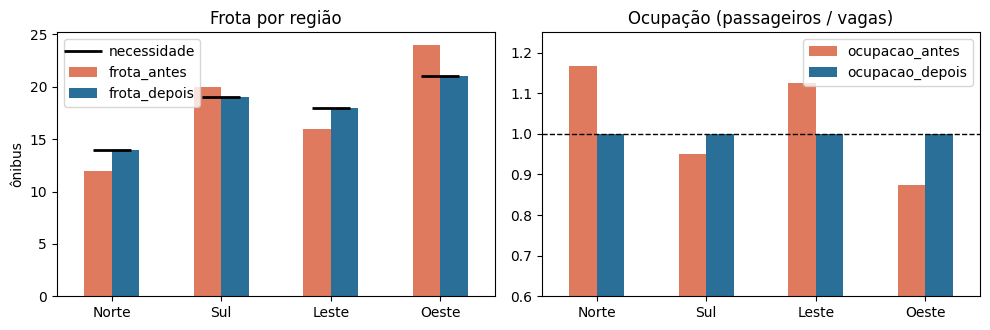

In [5]:
nova = np.rint(nova).astype(int)
res = pd.DataFrame({"passageiros": passageiros, "frota_antes": x, "frota_depois": nova, "variacao": nova - x,
                    "ocupacao_antes": passageiros / (CAPACIDADE * x), "ocupacao_depois": passageiros / (CAPACIDADE * nova),
                    "sem_vaga_antes": np.clip(passageiros - CAPACIDADE * x, 0, None),
                    "sem_vaga_depois": np.clip(passageiros - CAPACIDADE * nova, 0, None)}, index=regioes)
display(res.round(3))
print(f"frota: {x.sum()} -> {nova.sum()} | passageiros sem vaga: {res.sem_vaga_antes.sum()} -> {res.sem_vaga_depois.sum()} | "
      f"ônibus movimentados: {res.variacao.clip(lower=0).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
res[["frota_antes", "frota_depois"]].plot.bar(ax=ax[0], color=["#e07a5f", "#2a6f97"], rot=0)
ax[0].plot(range(4), necessidade, "k_", ms=28, mew=2, label="necessidade")
ax[0].set(title="Frota por região", ylabel="ônibus"); ax[0].legend()
res[["ocupacao_antes", "ocupacao_depois"]].plot.bar(ax=ax[1], color=["#e07a5f", "#2a6f97"], rot=0)
ax[1].axhline(1, color="k", lw=1, ls="--"); ax[1].set(title="Ocupação (passageiros / vagas)", ylim=(0.6, 1.25))
plt.tight_layout(); plt.show()

## Conclusão da Etapa 2
- **Diagnóstico:** Norte e Leste tinham déficit de 2 ônibus cada (160 passageiros sem vaga no total); Sul e Oeste tinham 4 ônibus de sobra.
- **Política:** quem tem sobra cede o excedente a quem tem falta, na proporção da falta. Representada pela matriz coluna-estocástica $T$.
- **Resultado:** frota de $(12, 20, 16, 24)$ para $(14, 19, 18, 21)$, com **4 ônibus movimentados**, total de 72 preservado e nenhum passageiro sem vaga. A ocupação máxima cai de 1,17 (Norte) para 1,00.
- **Garantias demonstradas:** conservação do total, não negatividade e resultado inteiro.

**Limitações.** O modelo supõe que cada ônibus atende só a região em que está alocado e que a demanda do pico é conhecida e fixa (hipóteses do enunciado). Ele não considera o custo de deslocar veículos entre centros nem a variação da demanda ao longo do dia. Regiões com ocupação exatamente 1,00 ficam sem folga: qualquer aumento de demanda gera passageiros sem vaga.